In [104]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.manifold import TSNE
from hdbscan import HDBSCAN
import seaborn as sns

In [2]:
clust, run = 'gspy', 'O3a'
filterr = True

base = "/home/esanches/Projetos/tSNE/Virgo"
teste = "/home/esanches/Projetos/tSNE/Virgo/zrepository/" + clust + "/" + run

suffix = "_filtered" if filterr else "_"

In [3]:
vecs_path = teste + "/" + "vecs" + suffix + ".npy"
labs_path = teste + "/" + "labs" + suffix + ".npy"
GPSs_path = teste + "/" + "GPSs" + suffix + ".npy"

In [4]:
vecs_path

'/home/esanches/Projetos/tSNE/Virgo/zrepository/gspy/O3a/vecs_filtered.npy'

## tSNE plots for O3a

In [5]:
perp = 100
dt = 2

In [6]:
final_vecs = np.load(vecs_path)
final_labs = np.load(labs_path)

le = LabelEncoder()
labels = le.fit_transform(final_labs.ravel())

final_GPS = np.load(GPSs_path)

tsne = TSNE(n_components=2, n_jobs=-1, verbose=0, perplexity=perp, learning_rate=200, max_iter=1000, metric="euclidean", random_state=42)
proj = tsne.fit_transform(final_vecs)

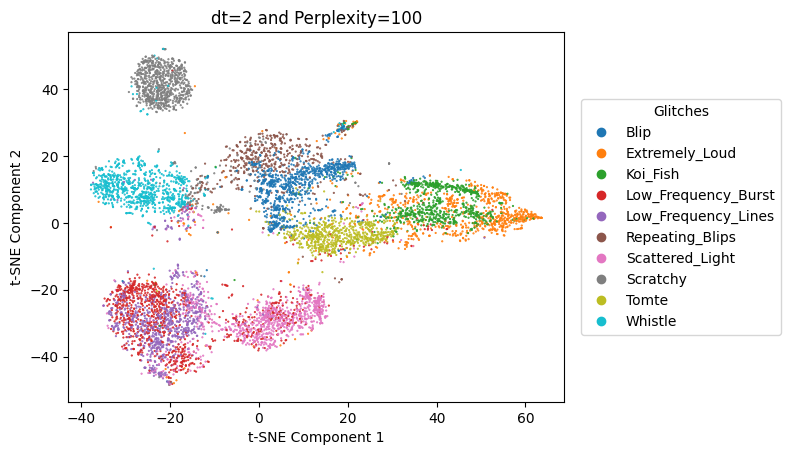

In [7]:
sc = plt.scatter(proj[:, 0], proj[:, 1], s=0.3, c=labels, cmap="tab10")
plt.title(f"dt={dt} and Perplexity={perp}", fontsize=12)
plt.xlabel("t-SNE Component 1", fontsize=10)
plt.ylabel("t-SNE Component 2", fontsize=10)

plt.legend(handles=sc.legend_elements()[0], labels=list(le.classes_), 
          title="Glitches", loc='center left', bbox_to_anchor=(1.02, 0.5))

plt.show()

### Analysis by month

In [10]:
o3a_intervals = {
    'Apr': (1238166018, 1240761618),
    'May': (1240761618, 1243440018),
    'Jun': (1243440018, 1246032018),
    'Jul': (1243440018, 1248710418),
    'Aug': (1248710418, 1251388818),
    'Sep': (1251388818, 1253980818)
}

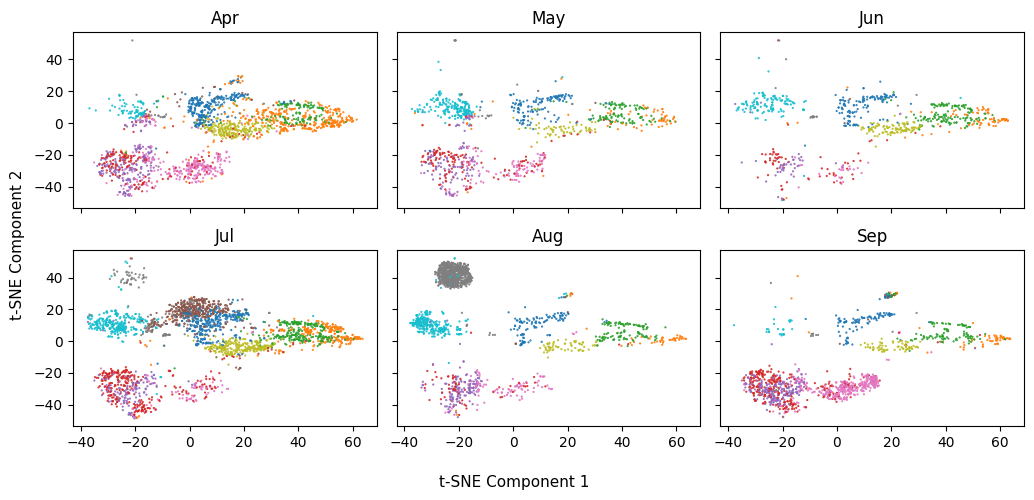

In [11]:
x_axis = int(np.ceil(len(o3a_intervals)/2))

fig, axs = plt.subplots(2, x_axis, figsize=(3.5*x_axis, 5), sharex=True, sharey=True)
axs = axs.flatten()

final_GPSs = np.load(GPSs_path)

for i, (m, (t_start, t_end)) in enumerate(o3a_intervals.items()):

    mask = ((final_GPSs >= t_start) & (final_GPSs <= t_end))

    data_dict = {
        'tsne_x': proj[mask, 0],
        'tsne_y': proj[mask, 1],
        'labels': final_labs[mask]
    }

    labels = le.fit_transform(data_dict['labels'].ravel())
    ax = axs[i]
    
    ax.scatter(data_dict['tsne_x'], data_dict['tsne_y'], s=0.3, c=labels, cmap="tab10")
    ax.set_title(f"{m}", fontsize=12)
    
    fig.supxlabel("t-SNE Component 1", fontsize=11)
    fig.supylabel("t-SNE Component 2", fontsize=11)

plt.tight_layout()
plt.show()

### HDBSCAN* for O3a

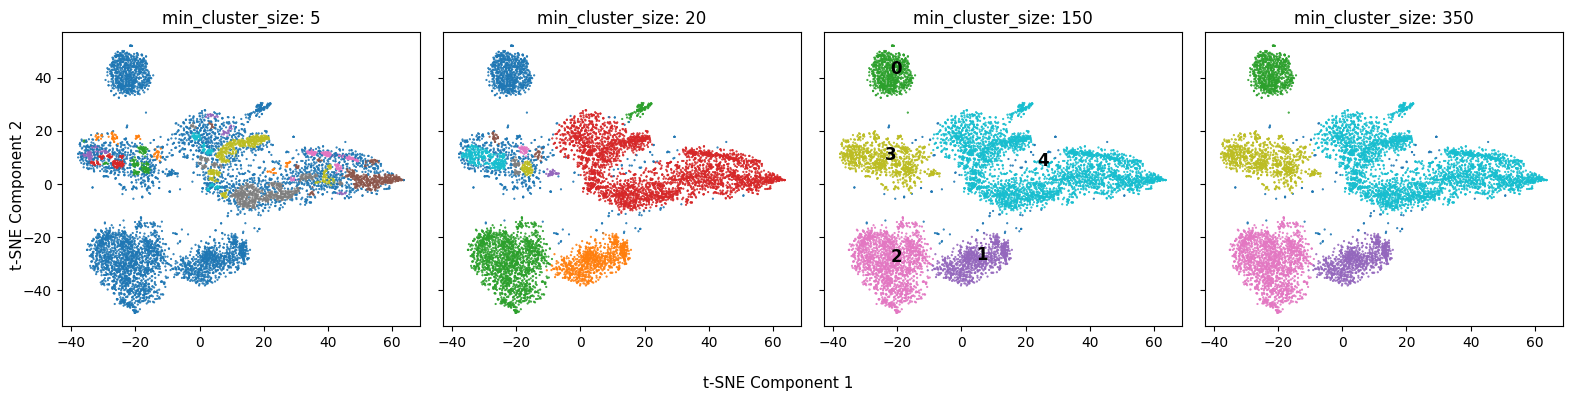

In [71]:
sizes = [5, 20, 150, 350]

fig, axs = plt.subplots(1, len(sizes), figsize=(4*len(sizes), 4), sharex=True, sharey=True)

for i, s in enumerate(sizes):

    hdbscan_labels = HDBSCAN(min_cluster_size=s, min_samples=10, gen_min_span_tree=True).fit_predict(proj)
    unique_labels = np.unique(hdbscan_labels)

    ax = axs[i]
    
    ax.scatter(proj[:, 0], proj[:, 1], s=0.3, c=hdbscan_labels, cmap="tab10")
    ax.set_title(f"min_cluster_size: {s}", fontsize=12)

    if s == 150:
        valid_clusters = [lbl for lbl in unique_labels if lbl > -1]
    
        for lbl in valid_clusters:
            proj_cluster = proj[hdbscan_labels == lbl]

            centroide_x = np.mean(proj_cluster[:, 0])
            centroide_y = np.mean(proj_cluster[:, 1])
            
            ax.text(centroide_x, centroide_y, str(lbl), fontsize=12, fontweight='bold', color='black')

fig.supxlabel("t-SNE Component 1", fontsize=11)
fig.supylabel("t-SNE Component 2", fontsize=11)

plt.tight_layout()
plt.show()

### Correspondence matrix

In [102]:
hdbscan_labels = HDBSCAN(min_cluster_size=150, min_samples=10).fit_predict(proj)

df_compare = pd.DataFrame({'GravitySpy': final_labs, 'HDBSCAN': hdbscan_labels})
mask = (df_compare['HDBSCAN'] != -1)
df_compare_off_noise = df_compare[mask]

matriz_normalizada = pd.crosstab(df_compare_off_noise['GravitySpy'], df_compare_off_noise['HDBSCAN'], normalize='index') * 100

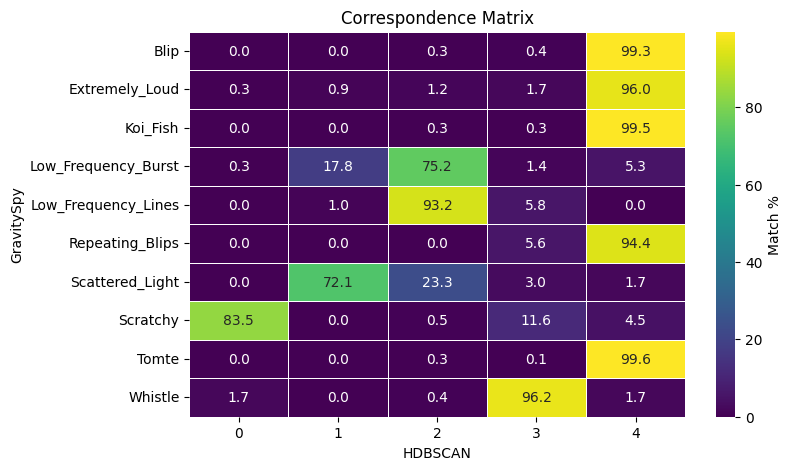

In [103]:
plt.figure(figsize=(8, 5))

sns.heatmap(matriz_normalizada, annot=True, cmap='viridis', fmt='.1f', linewidths=0.5, cbar_kws={'label': 'Match %'})

plt.title('Correspondence Matrix', fontsize=12)

plt.show()

## Analysis by weeks

We note that **Repeating_Blips appears in July** and **Scratchy appears in August**.

Scattered Light ~ September

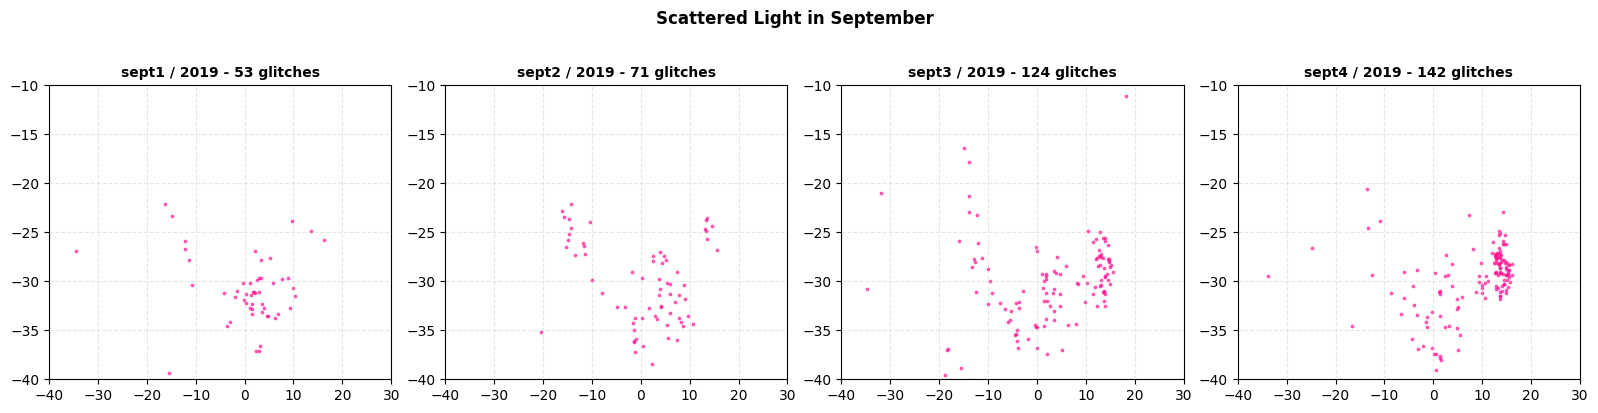

In [10]:
o3a_september_intervals = {
    'sept1': (1251331218, 1252000818),  # 01/Sep a 08/Sep (UTC)
    'sept2': (1252000818, 1252670418),  # 08/Sep a 15/Sep (UTC)
    'sept3': (1252670418, 1253340018),  # 15/Sep a 22/Sep (UTC)
    'sept4': (1253340018, 1254009618),  # 22/Sep a 29/Sep (UTC)
}
projs = gf.projections(repository, arq_name, dt, perp, o3a_september_intervals)
final_projs = {key: df[df['label'] == 'Scattered_Light'] for key, df in projs.items()}

gf.plot_saz(final_projs, 'Scattered Light in September', color='deeppink', xlim=(-40,30), ylim=(-40, -10))

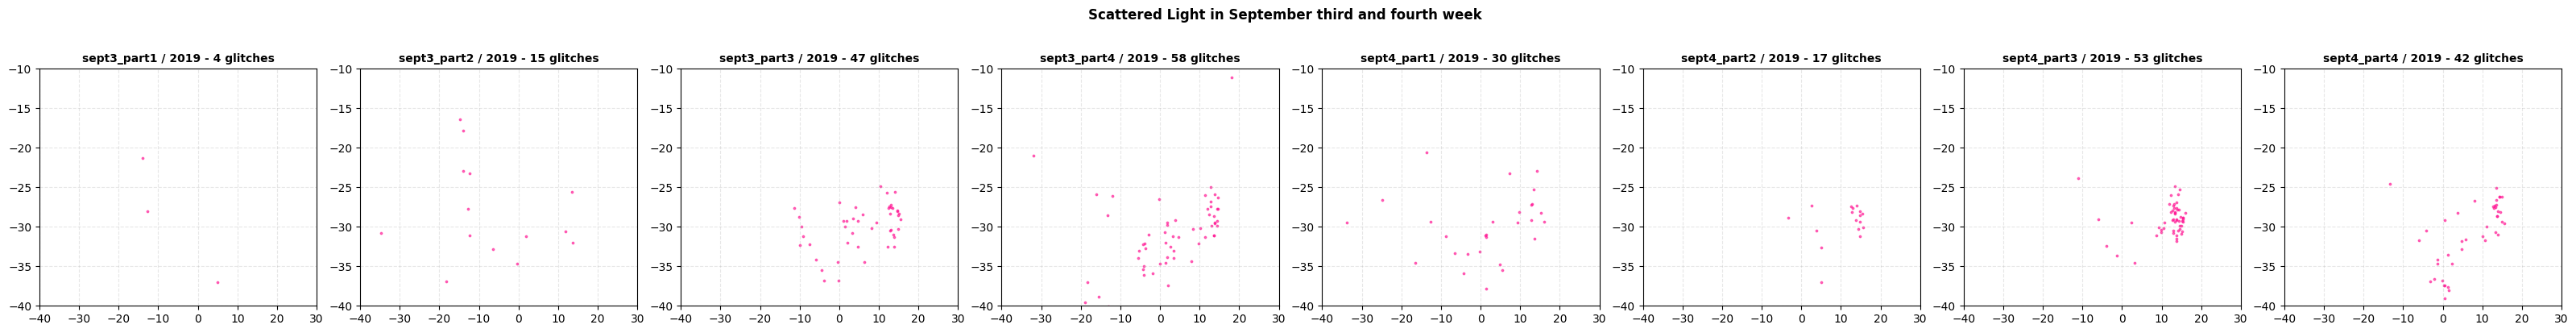

In [11]:
o3a_september_split_weeks = {
    'sept3_part1': (1252670418, 1252837818),
    'sept3_part2': (1252837818, 1253005218),
    'sept3_part3': (1253005218, 1253172618),
    'sept3_part4': (1253172618, 1253340018),
    
    'sept4_part1': (1253340018, 1253507418),
    'sept4_part2': (1253507418, 1253674818),
    'sept4_part3': (1253674818, 1253842218),
    'sept4_part4': (1253842218, 1254009618),
}
projs = gf.projections(repository, arq_name, dt, perp, o3a_september_split_weeks)
final_projs = {key: df[df['label'] == 'Scattered_Light'] for key, df in projs.items()}

gf.plot_saz(final_projs, 'Scattered Light in September third and fourth week', color='deeppink', xlim=(-40,30), ylim=(-40, -10))

Repeating_blips ~ July

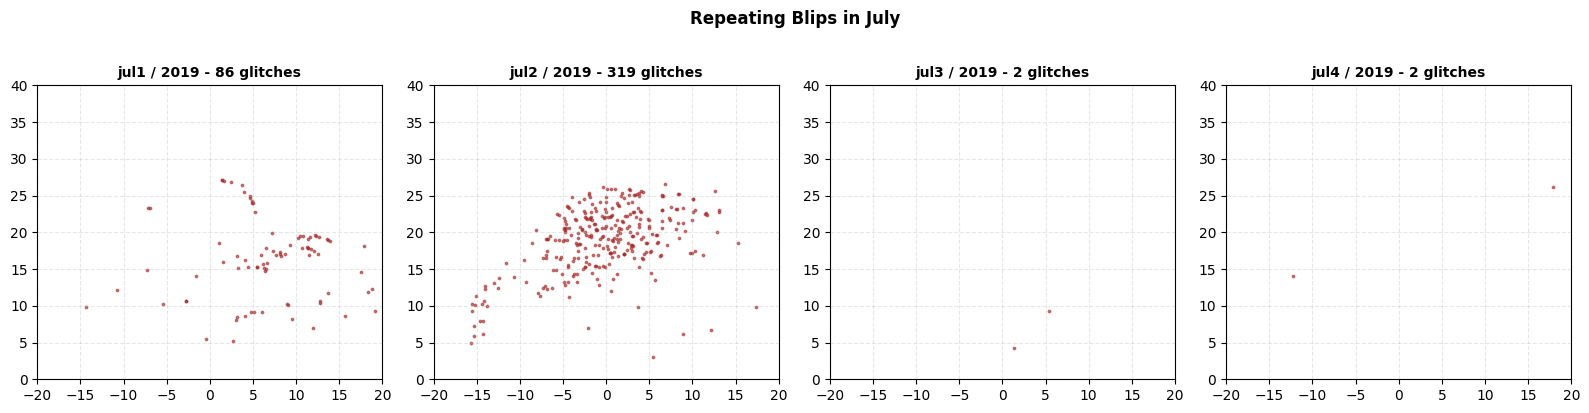

In [12]:
o3a_july_intervals = {
    'jul1': (1245974418, 1246644018),
    'jul2': (1246644018, 1247313618),
    'jul3': (1247313618, 1247983218),
    'jul4': (1247983218, 1248652818),
}
projs = gf.projections(repository, arq_name, dt, perp, o3a_july_intervals)
final_projs = {key: df[df['label'] == 'Repeating_Blips'] for key, df in projs.items()}

gf.plot_saz(final_projs, 'Repeating Blips in July', color='brown', xlim=(-20,20), ylim=(0, 40))

Repeating_blips ~ July second week

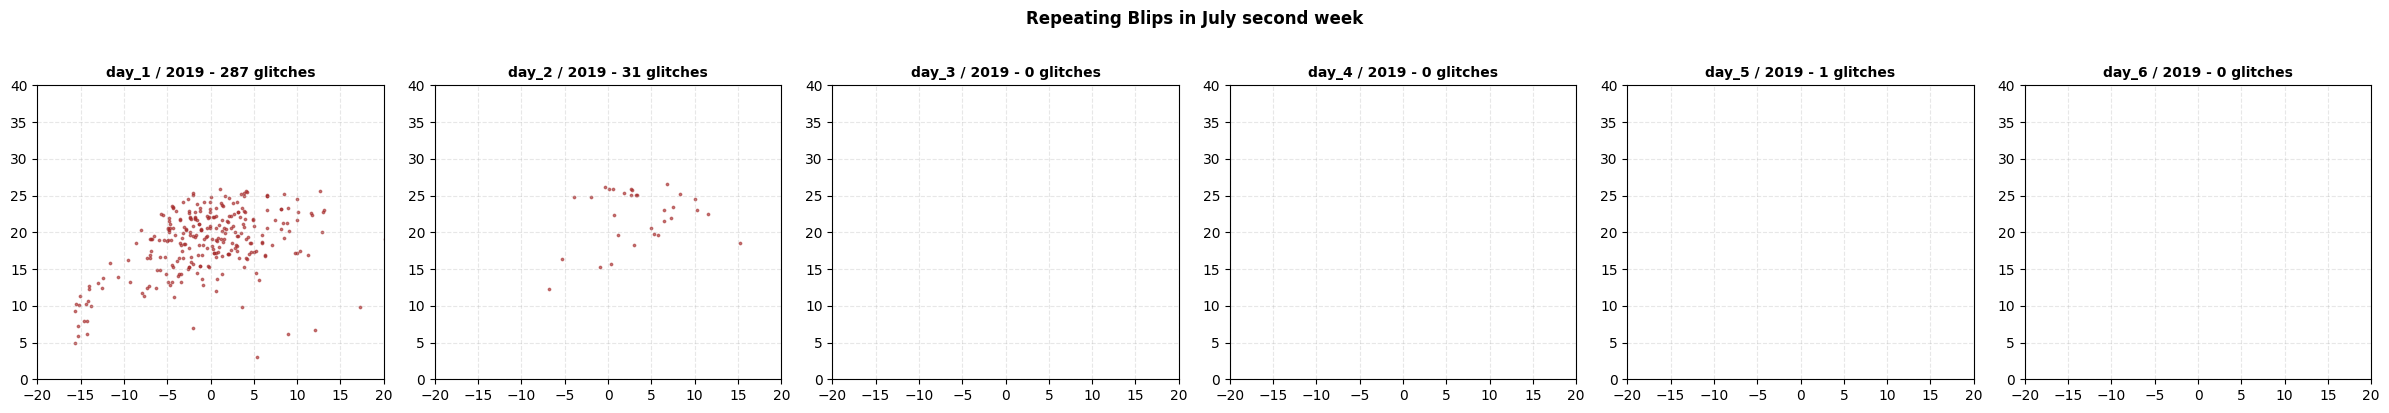

In [13]:
o3a_july_intervals = {
    'day_1': (1246644018, 1246739675),
    'day_2': (1246739675, 1246835332),
    'day_3': (1246835332, 1246930989),
    'day_4': (1246930989, 1247026646),
    'day_5': (1247026646, 1247122303),
    'day_6': (1247122303, 1247217960),
}
projs = gf.projections(repository, arq_name, dt, perp, o3a_july_intervals)
final_projs = {key: df[df['label'] == 'Repeating_Blips'] for key, df in projs.items()}

gf.plot_saz(final_projs, 'Repeating Blips in July second week', color='brown', xlim=(-20, 20), ylim=(0, 40))

Scratchy ~ August

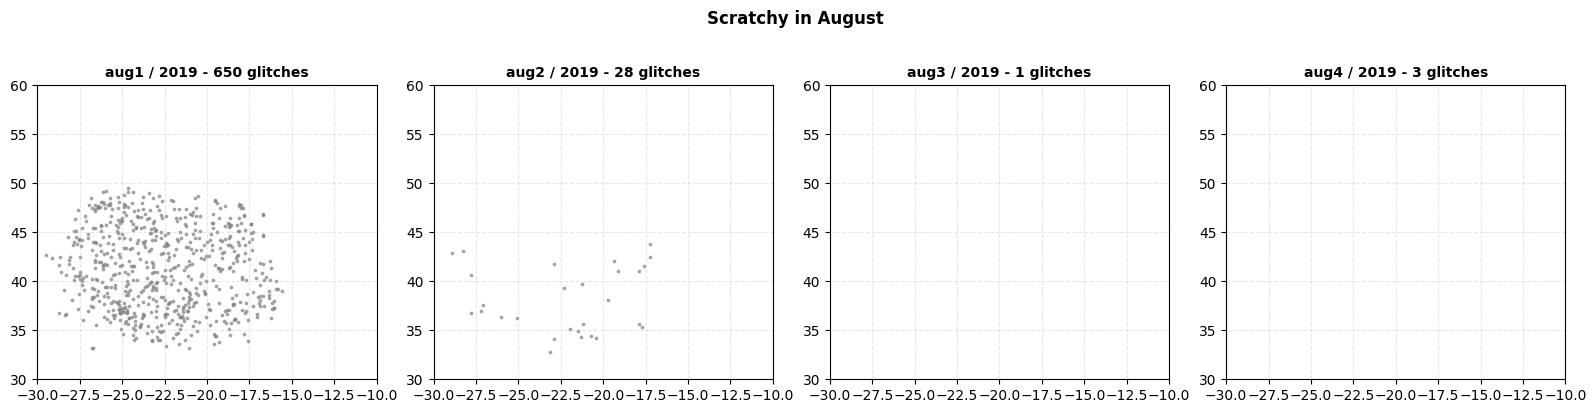

In [14]:
o3a_aug_intervals = {
    'aug1': (1248652818, 1249322418),
    'aug2': (1249322418, 1249992018),
    'aug3': (1249992018, 1250661618),
    'aug4': (1250661618, 1251331218),
}
projs = gf.projections(repository, arq_name, dt, perp, o3a_aug_intervals)
final_projs = {key: df[df['label'] == 'Scratchy'] for key, df in projs.items()}

gf.plot_saz(final_projs, 'Scratchy in August', color='gray', xlim=(-30,-10), ylim=(30,60))

Scratchy ~ August first week

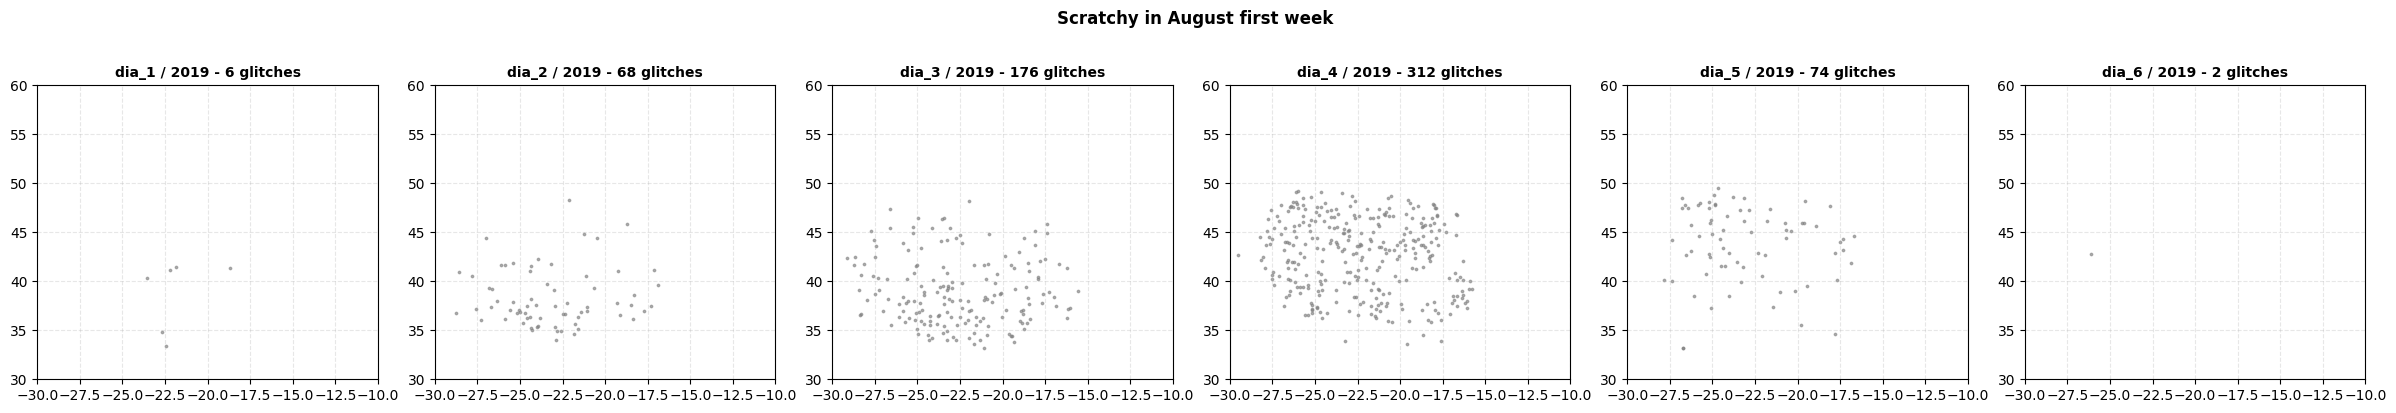

In [15]:
o3a_aug_intervals = {
    'dia_1': (1248652818, 1248748475),
    'dia_2': (1248748475, 1248844132),
    'dia_3': (1248844132, 1248939789),
    'dia_4': (1248939789, 1249035446),
    'dia_5': (1249035446, 1249131103),
    'dia_6': (1249131103, 1249226760),
}
projs = gf.projections(repository, arq_name, dt, perp, o3a_aug_intervals)
final_projs = {key: df[df['label'] == 'Scratchy'] for key, df in projs.items()}

gf.plot_saz(final_projs, 'Scratchy in August first week', color='gray', xlim=(-30,-10), ylim=(30,60))